# Análise exploratória da alfabetização no Brasil

## Objetivo
O desafio propõe prever se um aluno será alfabetizado usando dados da camada Gold da Fase 2. Nesta etapa, vamos conhecer as tabelas disponíveis e verificar o que elas permitem analisar.

## 1. Introdução
Vamos analisar os três arquivos Gold: municípios, UFs e Brasil. Vamos conferir valores ausentes, taxas, metas e mudanças entre os anos. Essas tabelas têm dados agrupados e não mostram o resultado de cada aluno.

## 2. Importando as bibliotecas
Pandas e NumPy organizam os dados. Matplotlib e Seaborn criam os gráficos. Também registramos as versões e as assinaturas dos arquivos para conferir se eles foram alterados.

In [1]:
from pathlib import Path
import hashlib
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda valor: f'{valor:,.3f}')
sns.set_theme(style='whitegrid', palette='muted')
cores_anos = {2023: '#4878A8', 2024: '#A87860', 2025: '#609078'}
plt.rcParams.update({'figure.figsize': (10, 5), 'figure.dpi': 110})
versoes = {nome: version(nome) for nome in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'nbformat', 'nbclient', 'ipykernel']}
display(pd.Series(versoes, name='versão'))

pandas         3.1.0
numpy          2.4.6
matplotlib    3.11.2
seaborn       0.13.2
nbformat      5.11.1
nbclient      0.11.0
ipykernel      7.4.0
Name: versão, dtype: str

Esta etapa analisa os dados e não treina modelos.

## 3. Carregando os dados
Vamos carregar os três CSVs de `data/gold/` e conferir as colunas que identificam cada registro.

In [21]:
raiz = Path.cwd()
if not (raiz / 'data' / 'gold').is_dir():
    raiz = raiz.parent
assert (raiz / 'data' / 'gold').is_dir(), 'Inicie na raiz do projeto ou em notebooks/.'
pasta_gold = raiz / 'data' / 'gold'
arquivos_gold = sorted(pasta_gold.glob('*.csv'))
assert len(arquivos_gold) > 0, 'Nenhum CSV Gold encontrado.'
arquivos_entrada = arquivos_gold
hashes_iniciais = {}
for caminho in arquivos_entrada:
    with caminho.open('rb') as arquivo:
        hashes_iniciais[str(caminho.relative_to(raiz))] = hashlib.file_digest(arquivo, 'sha256').hexdigest()
inventario = pd.DataFrame([
    {'arquivo': str(caminho.relative_to(raiz)), 'formato': caminho.suffix,
     'tamanho_MB': caminho.stat().st_size / 1_000_000}
    for caminho in arquivos_entrada
])
display(inventario)
dados_gold = {caminho.stem: pd.read_csv(caminho) for caminho in arquivos_gold}
municipios = dados_gold['indicadores_municipio']
ufs = dados_gold['indicadores_uf']
brasil = dados_gold['indicadores_brasil']
chaves = {
    'indicadores_municipio': ['ano', 'id_municipio', 'rede'],
    'indicadores_uf': ['ano', 'sigla_uf', 'rede'],
    'indicadores_brasil': ['ano', 'rede']
}
display(pd.DataFrame([
    {'dataset': nome, 'linhas': len(tabela), 'colunas': tabela.shape[1],
     'anos': str(sorted(tabela.ano.unique())), 'redes_observadas': str(sorted(tabela.rede.unique())),
     'chave_repetida': int(tabela.duplicated(chaves[nome]).sum())}
    for nome, tabela in dados_gold.items()
]))

,arquivo,formato,tamanho_MB
0,data\gold\indicadores_brasil.csv,.csv,0.001
1,data\gold\indicadores_municipio.csv,.csv,1.547
2,data\gold\indicadores_uf.csv,.csv,0.006


,dataset,linhas,colunas,anos,redes_observadas,chave_repetida
0,indicadores_brasil,3,15,"[np.int64(2023), np.int64(2024), np.int64(2025)]",[np.int64(5)],0
1,indicadores_municipio,10271,22,"[np.int64(2023), np.int64(2024)]",[np.int64(3)],0
2,indicadores_uf,49,17,"[np.int64(2023), np.int64(2024)]",[np.int64(5)],0


Cada linha representa um município, uma UF ou o Brasil, em um ano e uma rede. Vamos analisar as tabelas separadamente. A média simples das taxas municipais não é a taxa nacional.

## 4. Conhecendo as tabelas
Vamos observar as linhas, os tipos das colunas, os valores ausentes e os registros repetidos.

In [5]:
for nome, tabela in dados_gold.items():
    display(Markdown(f'### {nome}'))
    display(tabela.head(3))
    display(tabela.tail(3))
    estrutura = pd.DataFrame({
        'tipo': tabela.dtypes.astype(str),
        'distintos_sem_nulos': tabela.nunique(),
        'nulos': tabela.isna().sum(),
        'nulos_pct': tabela.isna().mean() * 100,
        'memoria_bytes': tabela.memory_usage(index=False, deep=True)
    })
    display(estrutura)
    display(Markdown(f'{len(tabela):,} linhas; {tabela.shape[1]} colunas; '
                     f'{tabela.duplicated().sum():,} duplicatas completas; '
                     f'{tabela.memory_usage(deep=True).sum()/1_000_000:.2f} MB em memória.'))

### indicadores_brasil

,ano,rede,taxa_oficial,percentual_participacao,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030,meta_do_ano,diferenca_para_meta,situacao_meta,_data_criacao_gold
0,2023,5,55.900,86.000,59.900,63.770,67.470,70.970,74.230,77.240,80.000,NaN,NaN,Sem meta,2026-11-03 01:04:36.459787
1,2024,5,59.200,87.370,59.900,63.770,67.470,70.970,74.230,77.240,80.000,59.900,-0.700,Não atingida,2026-11-03 01:04:36.459787
2,2025,5,66.000,88.000,60.000,64.000,67.000,71.000,74.000,77.000,80.000,64.000,2.000,Atingida,2026-11-03 01:04:36.459787


,ano,rede,taxa_oficial,percentual_participacao,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030,meta_do_ano,diferenca_para_meta,situacao_meta,_data_criacao_gold
0,2023,5,55.900,86.000,59.900,63.770,67.470,70.970,74.230,77.240,80.000,NaN,NaN,Sem meta,2026-11-03 01:04:36.459787
1,2024,5,59.200,87.370,59.900,63.770,67.470,70.970,74.230,77.240,80.000,59.900,-0.700,Não atingida,2026-11-03 01:04:36.459787
2,2025,5,66.000,88.000,60.000,64.000,67.000,71.000,74.000,77.000,80.000,64.000,2.000,Atingida,2026-11-03 01:04:36.459787


,tipo,distintos_sem_nulos,nulos,nulos_pct,memoria_bytes
ano,int64,3,0,0.000,24
rede,int64,1,0,0.000,24
taxa_oficial,float64,3,0,0.000,24
percentual_participacao,float64,3,0,0.000,24
meta_alfabetizacao_2024,float64,2,0,0.000,24
meta_alfabetizacao_2025,float64,2,0,0.000,24
meta_alfabetizacao_2026,float64,2,0,0.000,24
meta_alfabetizacao_2027,float64,2,0,0.000,24
meta_alfabetizacao_2028,float64,2,0,0.000,24
meta_alfabetizacao_2029,float64,2,0,0.000,24


3 linhas; 15 colunas; 0 duplicatas completas; 0.00 MB em memória.

### indicadores_municipio

... (5 outputs left out)

,ano,sigla_uf,rede,taxa_oficial,media_portugues,percentual_participacao,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030,meta_do_ano,diferenca_para_meta,situacao_meta,_data_criacao_gold
0,2023,AL,5,43.880,729.723,92.360,49.700,55.500,61.100,66.500,71.500,76.000,80.000,NaN,NaN,Sem meta,2026-11-03 01:04:36.097610
1,2023,AM,5,52.200,736.469,76.140,56.800,61.300,65.600,69.600,73.400,76.900,80.000,NaN,NaN,Sem meta,2026-11-03 01:04:36.097610
2,2023,AP,5,41.560,732.428,89.680,47.600,53.800,59.900,65.600,70.900,75.800,80.000,NaN,NaN,Sem meta,2026-11-03 01:04:36.097610


,ano,sigla_uf,rede,taxa_oficial,media_portugues,percentual_participacao,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030,meta_do_ano,diferenca_para_meta,situacao_meta,_data_criacao_gold
46,2024,SE,5,38.390,723.560,92.840,38.300,45.900,53.600,61.200,68.300,74.600,80.000,38.300,0.090,Atingida,2026-11-03 01:04:36.097610
47,2024,SP,5,58.130,749.896,89.120,56.600,61.100,65.400,69.500,73.300,76.800,80.000,56.600,1.530,Atingida,2026-11-03 01:04:36.097610
48,2024,TO,5,50.070,742.860,85.150,49.500,55.400,61.100,66.500,71.500,76.000,80.000,49.500,0.570,Atingida,2026-11-03 01:04:36.097610


,tipo,distintos_sem_nulos,nulos,nulos_pct,memoria_bytes
ano,int64,2,0,0.000,392
sigla_uf,str,25,0,0.000,2891
rede,int64,1,0,0.000,392
taxa_oficial,float64,49,0,0.000,392
media_portugues,float64,49,0,0.000,392
percentual_participacao,float64,48,0,0.000,392
meta_alfabetizacao_2024,float64,24,1,2.041,392
meta_alfabetizacao_2025,float64,25,0,0.000,392
meta_alfabetizacao_2026,float64,24,0,0.000,392
meta_alfabetizacao_2027,float64,23,0,0.000,392


49 linhas; 17 colunas; 0 duplicatas completas; 0.02 MB em memória.

## 5. Verificando problemas nos dados
Vamos conferir as chaves, os percentuais e os cálculos de taxas e metas, sem alterar os arquivos.

In [4]:
resumo_qualidade = []
# Percorre cada conjunto de dados da camada Gold
for nome, tabela in dados_gold.items():
    percentuais = [coluna for coluna in tabela if coluna.startswith('meta_alfabetizacao_')]
    percentuais += [coluna 
        for coluna in ['taxa_oficial','taxa_microdados','percentual_participacao','meta_do_ano']
            if coluna in tabela
    ]
    # Conta os valores percentuais menores que 0 ou maiores que 100
    fora_limite = (
        (tabela[percentuais] < 0) |
        (tabela[percentuais] > 100)
    ).sum().sum()

    meta_esperada = pd.Series(np.nan, index=tabela.index)

    # Percorre os anos disponíveis na tabela
    for ano in tabela.ano.unique():
        coluna_meta = f'meta_alfabetizacao_{ano}'
        if coluna_meta in tabela:
            mascara = tabela.ano.eq(ano)
            meta_esperada.loc[mascara] = tabela.loc[mascara, coluna_meta]
    meta_incorreta = ~np.isclose(
        tabela.meta_do_ano,
        meta_esperada,
        equal_nan=True,
        atol=0.011
    )
    diferenca_esperada = tabela.taxa_oficial - tabela.meta_do_ano
    diferenca_incorreta = ~np.isclose(
        tabela.diferenca_para_meta,
        diferenca_esperada,
        equal_nan=True,
        atol=0.011
    )
    situacao_esperada = np.where(
        diferenca_esperada.isna(),
        'Sem meta',
        np.where(
            diferenca_esperada >= 0,
            'Atingida',
            'Não atingida'
        )
    )
    categorias_texto = tabela.select_dtypes(
        include=['object', 'str']
    ).columns
    espacos = sum(
        int(
            tabela[coluna].dropna().astype(str).ne(
                tabela[coluna].dropna().astype(str).str.strip()
            ).sum()
        )
        for coluna in categorias_texto
    )

    # Armazena a quantidade de problemas encontrados em cada verificação
    resumo_qualidade.append({
        'dataset': nome,
        'duplicatas_completas': int(tabela.duplicated().sum()),
        'duplicatas_chave': int(tabela.duplicated(chaves[nome]).sum()),
        'nulos_na_chave': int(
            tabela[chaves[nome]].isna().any(axis=1).sum()
        ),
        'celulas_percentuais_invalidas': int(fora_limite),
        'meta_do_ano_divergente': int(meta_incorreta.sum()),
        'diferenca_divergente': int(diferenca_incorreta.sum()),
        'situacao_divergente': int(
            tabela.situacao_meta.ne(situacao_esperada).sum()
        ),
        'textos_com_espaco_externo': espacos,
        'data_criacao_invalida': int(
            pd.to_datetime(
                tabela['_data_criacao_gold'],
                errors='coerce'
            ).isna().sum()
        )
    })
display(pd.DataFrame(resumo_qualidade))

# VERIFICAÇÃO DOS DADOS DISPONÍVEIS POR ANO

# Percorre os dados da camada Gold
for nome, tabela in dados_gold.items():
    display(Markdown(f'Ausências por ano — {nome}'))
    display(
        tabela.groupby('ano').agg(
            registros=('ano', 'size'),
            taxa_disponivel=('taxa_oficial', 'count'),
            meta_disponivel=('meta_do_ano', 'count')
        )
    )
    display(
        tabela.groupby('ano')['situacao_meta']
        .value_counts()
        .unstack(fill_value=0)
    )
# VERIFICAÇÃO DOS DADOS DOS MUNICÍPIOS
taxa_recalculada = (
    municipios.alunos_alfabetizados /
    municipios.alunos_presentes * 100
)
display(
    pd.Series({
        'contagens_negativas': int(
            (
                municipios[
                    ['alunos_presentes', 'alunos_alfabetizados']
                ] < 0
            ).any(axis=1).sum()
        ),
        'alfabetizados_maior_que_presentes': int(
            (
                municipios.alunos_alfabetizados >
                municipios.alunos_presentes
            ).sum()
        ),
        'presentes_zero': int(
            municipios.alunos_presentes.eq(0).sum()
        ),
        'taxa_microdados_divergente_mais_001pp': int(
            (
                municipios.taxa_microdados - taxa_recalculada
            ).abs().gt(0.011).sum()
        ),
        'codigo_municipal_formato_invalido': int(
            (
                ~municipios.id_municipio.astype(str)
                .str.fullmatch(r'\d{7}')
            ).sum()
        )

    }, name='verificação')
)

,dataset,duplicatas_completas,duplicatas_chave,nulos_na_chave,celulas_percentuais_invalidas,meta_do_ano_divergente,diferenca_divergente,situacao_divergente,textos_com_espaco_externo,data_criacao_invalida
0,indicadores_brasil,0,0,0,0,0,0,0,0,0
1,indicadores_municipio,0,0,0,0,0,0,0,0,0
2,indicadores_uf,0,0,0,0,0,0,0,0,0


Ausências por ano — indicadores_brasil

,registros,taxa_disponivel,meta_disponivel
ano,,,
2023,1,1,0
2024,1,1,1
2025,1,1,1


situacao_meta,Sem meta,Não atingida,Atingida
ano,,,
2023,1,0,0
2024,0,1,0
2025,0,0,1


Ausências por ano — indicadores_municipio

,registros,taxa_disponivel,meta_disponivel
ano,,,
2023,4822,4821,0
2024,5449,5448,5232


situacao_meta,Atingida,Não atingida,Sem meta
ano,,,
2023,0,0,4822
2024,2788,2444,217


Ausências por ano — indicadores_uf

,registros,taxa_disponivel,meta_disponivel
ano,,,
2023,24,24,0
2024,25,25,24


situacao_meta,Atingida,Não atingida,Sem meta
ano,,,
2023,0,0,24
2024,11,13,1


contagens_negativas                      0
alfabetizados_maior_que_presentes        0
presentes_zero                           0
taxa_microdados_divergente_mais_001pp    0
codigo_municipal_formato_invalido        0
Name: verificação, dtype: int64

A diferença para a meta é a taxa oficial menos a meta do ano. A situação da meta vem dessa comparação. Em 2023, não há meta do próprio ano; em 2024, os valores ausentes precisam ser investigados.

As duas taxas já estão na Gold. Diferenças entre elas precisam de investigação e não significam, sozinhas, um erro nos dados.

In [5]:
comparacao_taxas = municipios.copy()
comparacao_taxas['diferenca_taxas_pp'] = comparacao_taxas.taxa_microdados - comparacao_taxas.taxa_oficial
display(comparacao_taxas.diferenca_taxas_pp.describe())
display(comparacao_taxas.loc[comparacao_taxas.diferenca_taxas_pp.abs().nlargest(10).index,
    ['ano', 'id_municipio', 'alunos_presentes', 'taxa_microdados', 'taxa_oficial', 'diferenca_taxas_pp']])

count   10,269.000
mean         0.214
std          1.517
min        -35.330
25%         -0.110
50%          0.020
75%          0.430
max         56.900
Name: diferenca_taxas_pp, dtype: float64

,ano,id_municipio,alunos_presentes,taxa_microdados,taxa_oficial,diferenca_taxas_pp
3680,2023,4205191,35,65.710,8.810,56.900
922,2023,2305100,71,56.340,91.670,-35.330
4550,2023,5107578,16,56.250,29.040,27.210
2802,2023,3153103,10,30.000,57.140,-27.140
2731,2023,3146701,39,53.850,26.990,26.860
3835,2023,4216008,25,84.000,62.120,21.880
2408,2023,3119302,92,63.040,41.880,21.160
2949,2023,3165552,23,30.430,48.720,-18.290
106,2023,1304005,106,52.830,35.750,17.080
3754,2023,4210555,18,72.220,88.230,-16.010


## 6. Resumindo os valores
Vamos calcular estatísticas das medidas, deixando códigos e datas de fora. Diferenças entre taxas são medidas em pontos percentuais (p.p.). Na média simples municipal, todos os municípios têm o mesmo peso.

In [6]:
medidas_por_tabela = {}
for nome, tabela in dados_gold.items():
    medidas = [coluna for coluna in tabela.select_dtypes('number')
               if coluna not in ['ano', 'id_municipio', 'rede', 'nivel_alfabetizacao']]
    medidas_por_tabela[nome] = medidas
    numericas = tabela[medidas]
    estatisticas = numericas.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
    estatisticas['variancia'] = numericas.var()
    estatisticas['amplitude'] = numericas.max() - numericas.min()
    estatisticas['assimetria'] = numericas.skew()
    estatisticas['modas'] = [numericas[coluna].mode().tolist()[:5] for coluna in medidas]
    estatisticas['quantidade_modas'] = [len(numericas[coluna].mode()) for coluna in medidas]
    display(Markdown(f'Estatísticas — {nome}'))
    display(estatisticas)
    categoricas = [coluna for coluna in ['rede', 'sigla_uf', 'nivel_alfabetizacao', 'situacao_meta'] if coluna in tabela]
    for coluna in categoricas:
        contagem = tabela[coluna].value_counts(dropna=False)
        frequencias = contagem.to_frame(name='frequencia_absoluta')
        frequencias['frequencia_relativa_pct'] = frequencias.frequencia_absoluta / len(tabela) * 100
        display(Markdown(f'Categorias de `{coluna}` — {nome}'))
        display(frequencias)

Estatísticas — indicadores_brasil

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,variancia,amplitude,assimetria,modas,quantidade_modas
taxa_oficial,3.000,60.367,5.150,55.900,55.966,56.230,57.550,59.200,62.600,65.320,65.864,66.000,26.523,10.100,0.967,"[55.9, 59.2, 66.0]",3
percentual_participacao,3.000,87.123,1.023,86.000,86.027,86.137,86.685,87.370,87.685,87.937,87.987,88.000,1.046,2.000,-1.022,"[86.0, 87.37, 88.0]",3
meta_alfabetizacao_2024,3.000,59.933,0.058,59.900,59.900,59.900,59.900,59.900,59.950,59.990,59.998,60.000,0.003,0.100,1.732,[59.9],1
meta_alfabetizacao_2025,3.000,63.847,0.133,63.770,63.770,63.770,63.770,63.770,63.885,63.977,63.995,64.000,0.018,0.230,1.732,[63.77],1
meta_alfabetizacao_2026,3.000,67.313,0.271,67.000,67.009,67.047,67.235,67.470,67.470,67.470,67.470,67.470,0.074,0.470,-1.732,[67.47],1
meta_alfabetizacao_2027,3.000,70.980,0.017,70.970,70.970,70.970,70.970,70.970,70.985,70.997,70.999,71.000,0.000,0.030,1.732,[70.97],1
meta_alfabetizacao_2028,3.000,74.153,0.133,74.000,74.005,74.023,74.115,74.230,74.230,74.230,74.230,74.230,0.018,0.230,-1.732,[74.23],1
meta_alfabetizacao_2029,3.000,77.160,0.139,77.000,77.005,77.024,77.120,77.240,77.240,77.240,77.240,77.240,0.019,0.240,-1.732,[77.24],1
meta_alfabetizacao_2030,3.000,80.000,0.000,80.000,80.000,80.000,80.000,80.000,80.000,80.000,80.000,80.000,0.000,0.000,NaN,[80.0],1
meta_do_ano,2.000,61.950,2.899,59.900,59.941,60.105,60.925,61.950,62.975,63.795,63.959,64.000,8.405,4.100,NaN,"[59.9, 64.0]",2


Categorias de `rede` — indicadores_brasil

,frequencia_absoluta,frequencia_relativa_pct
rede,,
5,3,100.000


Categorias de `situacao_meta` — indicadores_brasil

,frequencia_absoluta,frequencia_relativa_pct
situacao_meta,,
Sem meta,1,33.333
Não atingida,1,33.333
Atingida,1,33.333


... (12 outputs left out)

Categorias de `sigla_uf` — indicadores_uf

,frequencia_absoluta,frequencia_relativa_pct
sigla_uf,,
AL,2,4.082
AM,2,4.082
AP,2,4.082
BA,2,4.082
CE,2,4.082
ES,2,4.082
GO,2,4.082
MA,2,4.082
MG,2,4.082


Categorias de `situacao_meta` — indicadores_uf

,frequencia_absoluta,frequencia_relativa_pct
situacao_meta,,
Sem meta,25,51.020
Não atingida,13,26.531
Atingida,11,22.449


A média e a mediana mostram valores centrais. O desvio padrão mostra quanto os valores variam. Os percentis ajudam a observar valores baixos e altos, e a moda mostra os mais frequentes.

A tabela nacional tem apenas três registros, o que limita as comparações.

## 7. Analisando cada informação
Vamos comparar taxas, quantidade de presentes e metas por ano. A escala logarítmica facilita a visualização de municípios pequenos e grandes.

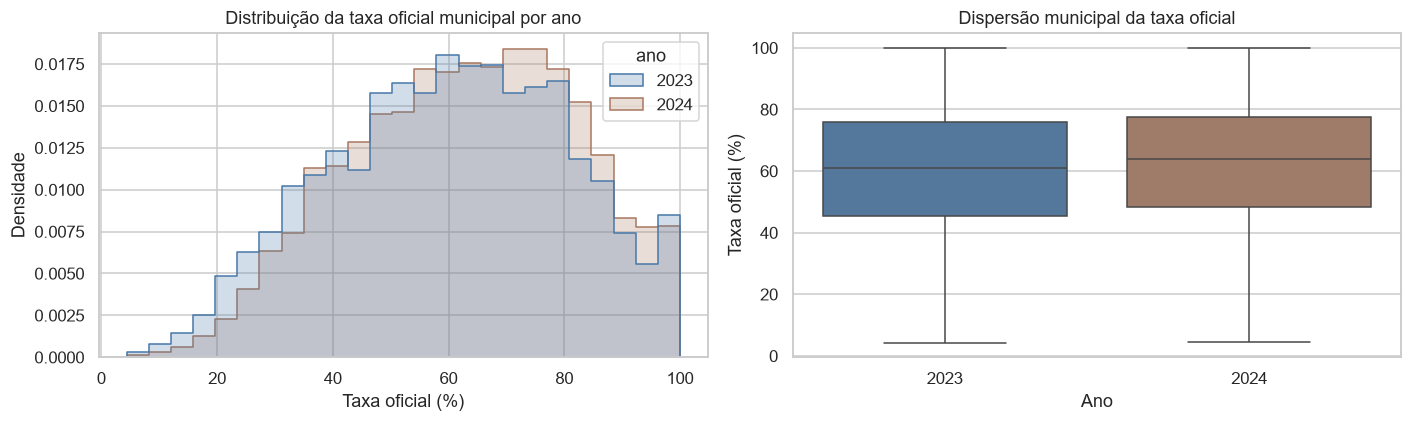

,count,mean,median,std,min,max
ano,,,,,,
2023,4821,60.180,61.040,20.391,4.350,100.000
2024,5448,62.800,64.050,19.342,4.400,100.000


In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=municipios, x='taxa_oficial', hue='ano', palette=cores_anos, bins=25, element='step', stat='density', common_norm=False, ax=eixos[0])
eixos[0].set(title='Distribuição da taxa oficial municipal por ano', xlabel='Taxa oficial (%)', ylabel='Densidade')
sns.boxplot(data=municipios, x='ano', y='taxa_oficial', hue='ano', palette=cores_anos, legend=False, ax=eixos[1])
eixos[1].set(title='Dispersão municipal da taxa oficial', xlabel='Ano', ylabel='Taxa oficial (%)')
plt.tight_layout()
plt.show()
display(municipios.groupby('ano').taxa_oficial.agg(['count', 'mean', 'median', 'std', 'min', 'max']))

A mediana municipal passa de 61,04% em 2023 para 64,05% em 2024. O desvio padrão cai de 20,39 para 19,34 p.p. Os municípios disponíveis mudam entre os anos, então vamos comparar também aqueles que aparecem nos dois períodos.

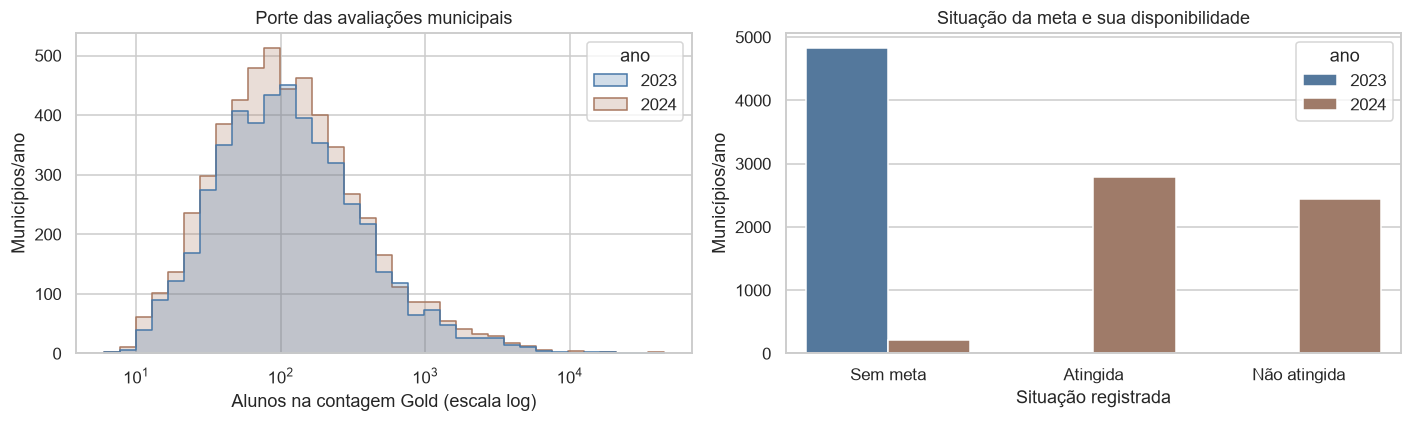

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=municipios, x='alunos_presentes', hue='ano', palette=cores_anos, bins=35, log_scale=True, element='step', ax=eixos[0])
eixos[0].set(title='Porte das avaliações municipais', xlabel='Alunos na contagem Gold (escala log)', ylabel='Municípios/ano')
sns.countplot(data=municipios, x='situacao_meta', hue='ano', palette=cores_anos, ax=eixos[1])
eixos[1].set(title='Situação da meta e sua disponibilidade', xlabel='Situação registrada', ylabel='Municípios/ano')
plt.tight_layout()
plt.show()

“Sem meta” indica falta de informação para comparar o resultado. Essa categoria deve ficar separada de “Atingida” e “Não atingida”.

## 8. Comparando as informações
Usamos a correlação de Spearman para observar se duas medidas aumentam ou diminuem juntas. Códigos e metas futuras ficam fora dessa comparação. A tabela abaixo de cada gráfico mostra quantos registros têm as duas medidas disponíveis.

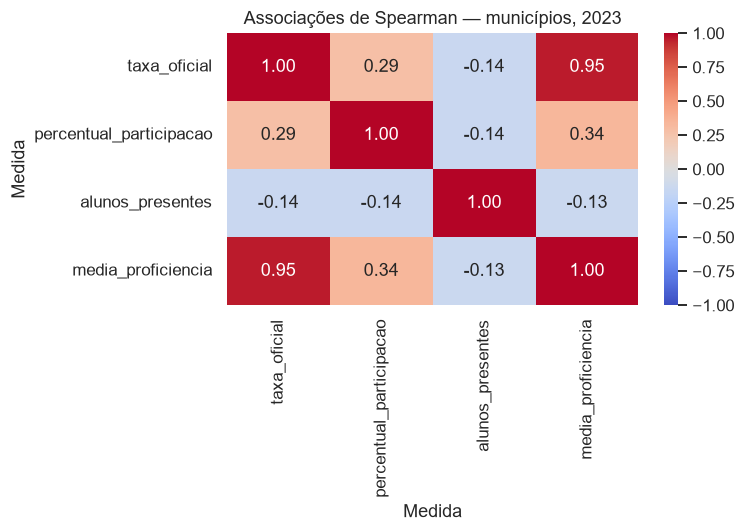

,taxa_oficial,percentual_participacao,alunos_presentes,media_proficiencia
N por par,,,,
taxa_oficial,4821,4611,4821,4821
percentual_participacao,4611,4611,4611,4611
alunos_presentes,4821,4611,4822,4822
media_proficiencia,4821,4611,4822,4822


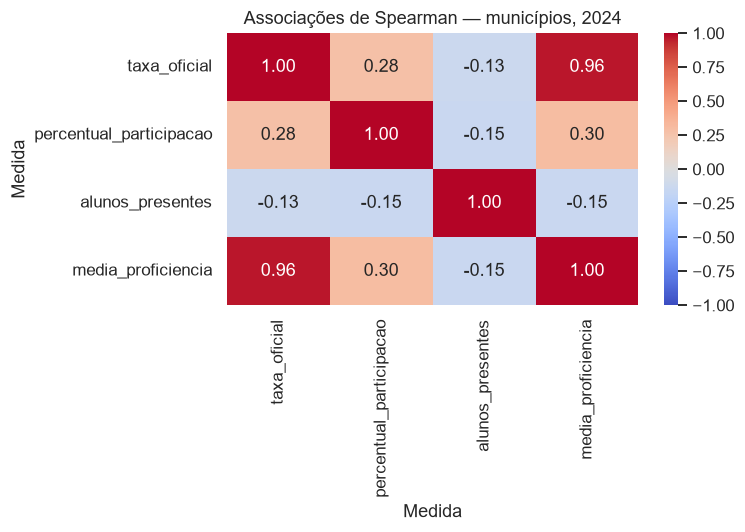

,taxa_oficial,percentual_participacao,alunos_presentes,media_proficiencia
N por par,,,,
taxa_oficial,5448,5352,5448,5448
percentual_participacao,5352,5352,5352,5352
alunos_presentes,5448,5352,5449,5449
media_proficiencia,5448,5352,5449,5449


In [9]:
variaveis_relacao = ['taxa_oficial', 'percentual_participacao', 'alunos_presentes', 'media_proficiencia']
correlacoes_por_ano = {}
for ano, grupo in municipios.groupby('ano'):
    correlacao = grupo[variaveis_relacao].corr(method='spearman')
    correlacoes_por_ano[int(ano)] = correlacao
    disponiveis = grupo[variaveis_relacao].notna().astype(int)
    tamanho_pares = disponiveis.T.dot(disponiveis)
    fig, eixo = plt.subplots(figsize=(7, 5))
    sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=eixo)
    eixo.set(title=f'Associações de Spearman — municípios, {ano}', xlabel='Medida', ylabel='Medida')
    plt.tight_layout()
    plt.show()
    display(tamanho_pares.rename_axis('N por par'))

Proficiência e taxa de alfabetização vêm da mesma avaliação. Uma relação forte entre elas não prova causa e efeito. Usar resultados do mesmo período para antecipar o alvo pode revelar a resposta ao modelo.

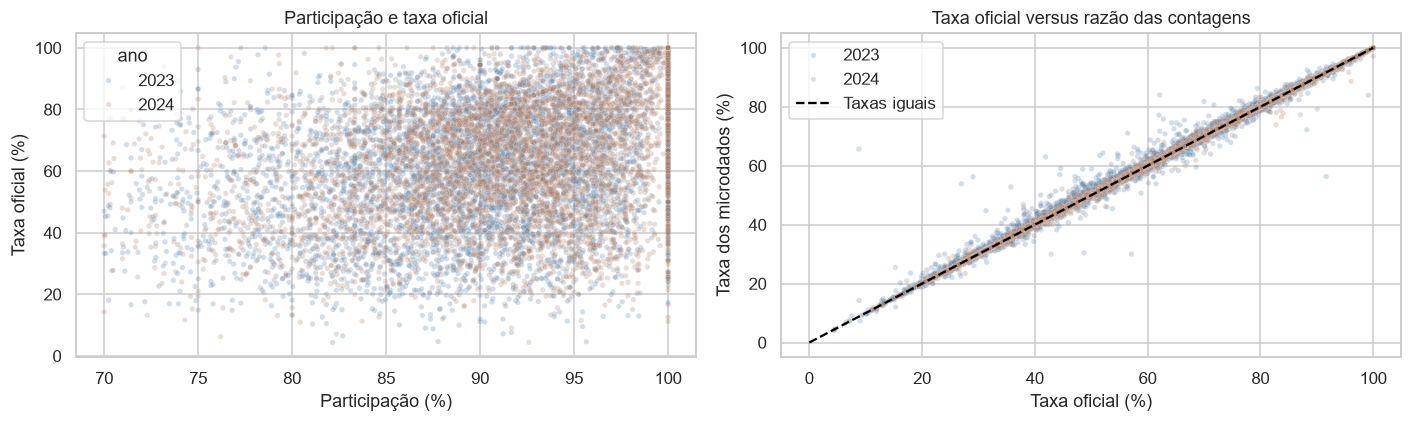

municipios  presentes_min  presentes_max  taxa_mediana  \
ano  faixa_porte                                                           
2023 0                  1225              6             51        68.050   
     1                  1186             52            105        61.440   
     2                  1209            106            237        59.090   
     3                  1202            238          44858        57.260   
2024 0                  1371              6             50        67.870   
     1                  1368             51            103        66.740   
     2                  1354            104            231        63.145   
     3                  1356            232          43340        59.495   

                  participacao_mediana  
ano  faixa_porte                        
2023 0                          91.110  
     1                          90.910  
     2                          90.800  
     3                          88.720  
2024 0                          92.590  
     1                          92.930  
     2                          92.000  
     3                          90.305

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=municipios, x='percentual_participacao', y='taxa_oficial', hue='ano', palette=cores_anos, alpha=.25, s=12, ax=eixos[0])
eixos[0].set(title='Participação e taxa oficial', xlabel='Participação (%)', ylabel='Taxa oficial (%)')
sns.scatterplot(data=comparacao_taxas, x='taxa_oficial', y='taxa_microdados', hue='ano', palette=cores_anos, alpha=.25, s=12, ax=eixos[1])
eixos[1].plot([0, 100], [0, 100], color='black', linestyle='--', label='Taxas iguais')
eixos[1].set(title='Taxa oficial versus razão das contagens', xlabel='Taxa oficial (%)', ylabel='Taxa dos microdados (%)')
eixos[1].legend()
plt.tight_layout()
plt.show()

# Faixas de porte são descritivas: quartis da contagem dentro de cada ano.
comparacao_porte = municipios.copy()
comparacao_porte['faixa_porte'] = comparacao_porte.groupby('ano')['alunos_presentes'].transform(
    lambda serie: pd.qcut(serie, q=4, labels=False, duplicates='drop'))
display(comparacao_porte.groupby(['ano', 'faixa_porte']).agg(
    municipios=('id_municipio', 'size'), presentes_min=('alunos_presentes', 'min'),
    presentes_max=('alunos_presentes', 'max'), taxa_mediana=('taxa_oficial', 'median'),
    participacao_mediana=('percentual_participacao', 'median')))

A diagonal marca onde as taxas seriam iguais. As faixas de porte dividem os municípios em quatro grupos pela quantidade de presentes de cada ano. Elas são descritivas e não representam regiões.

## 9. Verificando valores extremos
Usamos a regra do intervalo interquartil (IQR), que considera a distância entre os quartis de 25% e 75%. Valores além de 1,5 vez esse intervalo abaixo ou acima dos quartis são sinalizados. Nenhum registro será removido automaticamente.

In [11]:
outliers = []
for ano, grupo in municipios.groupby('ano'):
    for coluna in ['taxa_oficial', 'alunos_presentes', 'percentual_participacao', 'media_proficiencia']:
        serie = grupo[coluna].dropna()
        q1, q3 = serie.quantile([.25, .75])
        intervalo = q3 - q1
        limite_inferior = q1 - 1.5 * intervalo
        limite_superior = q3 + 1.5 * intervalo
        mascara = (serie < limite_inferior) | (serie > limite_superior)
        outliers.append({'ano': ano, 'variavel': coluna, 'n_validos': len(serie),
                         'limite_inferior': limite_inferior, 'limite_superior': limite_superior,
                         'outliers': int(mascara.sum()), 'outliers_pct': mascara.mean() * 100})
resumo_outliers = pd.DataFrame(outliers)
display(resumo_outliers)
display(municipios.nlargest(8, 'alunos_presentes')[['ano', 'id_municipio', 'alunos_presentes', 'taxa_oficial']])

,ano,variavel,n_validos,limite_inferior,limite_superior,outliers,outliers_pct
0,2023,taxa_oficial,4821,-0.560,121.680,0,0.000
1,2023,alunos_presentes,4822,-228.000,516.000,481,9.975
2,2023,percentual_participacao,4611,72.795,107.395,47,1.019
3,2023,media_proficiencia,4822,690.528,807.918,147,3.049
4,2024,taxa_oficial,5448,4.311,121.561,0,0.000
5,2024,alunos_presentes,5449,-221.500,502.500,585,10.736
6,2024,percentual_participacao,5352,74.416,108.666,84,1.570
7,2024,media_proficiencia,5449,696.350,806.878,149,2.734


,ano,id_municipio,alunos_presentes,taxa_oficial
3175,2023,3304557,44858,56.190
8013,2024,3304557,43340,63.750
8585,2024,3550308,41757,48.250
89,2023,1302603,18951,52.200
912,2023,2304400,18800,74.030
4933,2024,1302603,18666,50.130
5756,2024,2304400,17571,74.810
2124,2023,2927408,13442,39.160


A regra não sinalizou valores extremos na taxa oficial. Nas contagens de presentes, foram 481 registros em 2023 e 585 em 2024. Municípios grandes podem explicar parte desses valores. Precisamos investigar antes de excluir registros.

## 10. Comparando os anos
Vamos comparar os municípios com taxa nos dois anos e conferir a cobertura das UFs. O período disponível é curto para avaliar tendências de longo prazo.

In [ ]:
len()
ufs_brasileiras = set(
    'AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO'.split())
len(ufs_brasileiras)

27

,linhas,municipios_distintos
ano,,
2023,4822,4822
2024,5449,5449


,ufs_disponiveis
ano,
2023,24
2024,25


,ano,ufs_ausentes
0,2023,"AC, DF, RR"
1,2024,"DF, RR"


indicadores_brasil: anos [2023, 2024, 2025]; lacunas internas [].

indicadores_municipio: anos [2023, 2024]; lacunas internas [].

indicadores_uf: anos [2023, 2024]; lacunas internas [].

2023   2024 
True   True     4772
False  True      676
True   False      49
Name: municipios_por_padrao_de_cobertura, dtype: int64

count   4,772.000
mean        2.613
std        17.071
min       -83.830
25%        -6.343
50%         2.400
75%        12.265
max        89.930
Name: variacao_pp, dtype: float64

,ano,2023,2024,variacao_pp
id_municipio,rede,,,
2515005,3,10.070,100.000,89.930
5101209,3,22.220,100.000,77.780
2101939,3,12.840,87.880,75.040
2206753,3,21.740,95.240,73.500
2515807,3,14.550,85.710,71.160


,ano,2023,2024,variacao_pp
id_municipio,rede,,,
4301750,3,88.230,4.400,-83.830
4301073,3,94.580,18.200,-76.380
4319752,3,100.000,25.000,-75.000
4320453,3,85.410,11.100,-74.310
4302584,3,100.000,27.300,-72.700


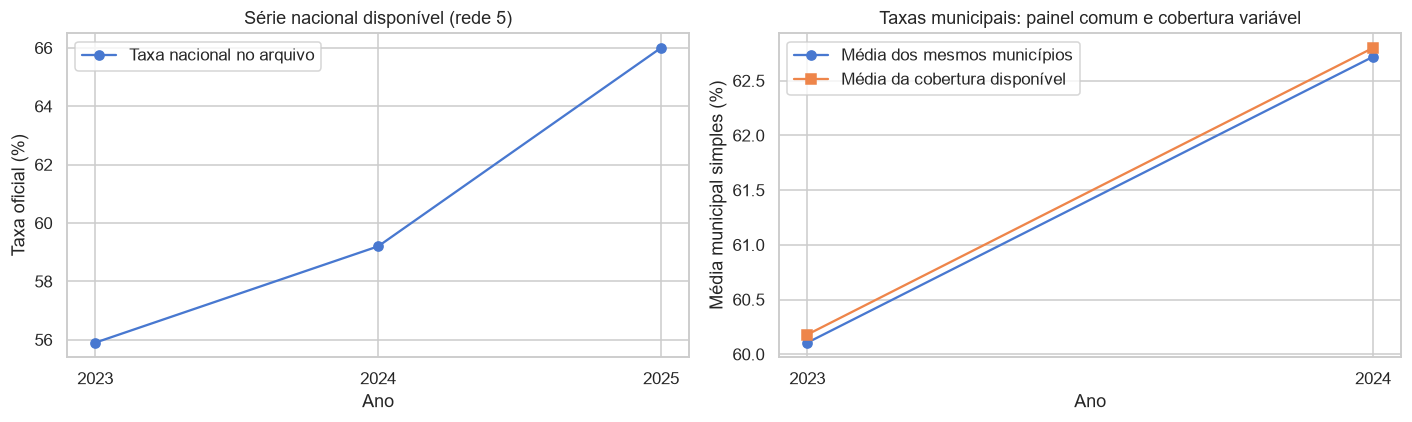

In [18]:
display(municipios.groupby('ano').agg(linhas=('ano', 'size'), municipios_distintos=('id_municipio', 'nunique')))
display(ufs.groupby('ano').agg(ufs_disponiveis=('sigla_uf', 'nunique')))
ufs_brasileiras = set('AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO'.split())
display(pd.DataFrame([{'ano': ano, 'ufs_ausentes': ', '.join(sorted(ufs_brasileiras - set(grupo.sigla_uf)))} for ano, grupo in ufs.groupby('ano')]))
for nome, tabela in dados_gold.items():
    anos = sorted(int(ano) for ano in tabela.ano.unique())
    lacunas = sorted(set(range(int(min(anos)), int(max(anos)) + 1)) - set(anos))
    display(Markdown(f'{nome}: anos {anos}; lacunas internas {lacunas}.'))

painel = municipios.pivot(index=['id_municipio', 'rede'], columns='ano', values='taxa_oficial')
display(painel.notna().value_counts().rename('municipios_por_padrao_de_cobertura'))
painel_completo = painel.dropna(subset=[2023, 2024]).copy()
painel_completo['variacao_pp'] = painel_completo[2024] - painel_completo[2023]
display(painel_completo.variacao_pp.describe())
display(painel_completo.nlargest(5, 'variacao_pp'))
display(painel_completo.nsmallest(5, 'variacao_pp'))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].plot(brasil.ano, brasil.taxa_oficial, marker='o', label='Taxa nacional no arquivo')
eixos[0].set(title='Série nacional disponível (rede 5)', xlabel='Ano', ylabel='Taxa oficial (%)', xticks=sorted(brasil.ano.unique()))
eixos[0].legend()
eixos[1].plot([2023, 2024], painel_completo[[2023, 2024]].mean(), marker='o', label='Média dos mesmos municípios')
eixos[1].plot([2023, 2024], municipios.groupby('ano').taxa_oficial.mean().reindex([2023, 2024]), marker='s', label='Média da cobertura disponível')
eixos[1].set(title='Taxas municipais: painel comum e cobertura variável', xlabel='Ano', ylabel='Média municipal simples (%)', xticks=[2023, 2024])
eixos[1].legend()
plt.tight_layout()
plt.show()

Nos 4.772 municípios/rede com taxa nos dois anos, o aumento médio foi de 2,61 p.p. Isso não significa que todos melhoraram, nem representa a taxa nacional.

Na tabela de UF, faltam AC, DF e RR em 2023 e DF e RR em 2024. Ausência de registro não significa taxa zero. O dado nacional de 2025 aparece apenas na tabela do Brasil e não permite comparar municípios nesse ano.

## 11. Preparando a próxima etapa
Vamos conferir o cumprimento da meta municipal e identificar colunas com pouca variação. A Gold permite analisar municípios, mas não classificar alunos individualmente. O próximo notebook trabalha com risco municipal usando informações do ano anterior.

In [13]:
distribuicoes_alvo = []
for nome, serie in [
    ('Gold municipal: meta conhecida', municipios.loc[municipios.situacao_meta.ne('Sem meta'), 'situacao_meta'])
]:
    frequencia = serie.value_counts(dropna=False)
    for classe, quantidade in frequencia.items():
        distribuicoes_alvo.append({'recorte': nome, 'classe': classe, 'n': quantidade, 'percentual': quantidade / len(serie) * 100})
display(pd.DataFrame(distribuicoes_alvo))
display(pd.DataFrame([
    {'dataset': nome, 'coluna': coluna, 'distintos': tabela[coluna].nunique(dropna=False),
     'categoria_dominante_pct': tabela[coluna].value_counts(dropna=False, normalize=True).iloc[0] * 100}
    for nome, tabela in dados_gold.items() for coluna in tabela
    if tabela[coluna].nunique(dropna=False) <= 2 or tabela[coluna].value_counts(dropna=False, normalize=True).iloc[0] >= .95
]))
pares_fortes = []
for ano, correlacao in correlacoes_por_ano.items():
    for posicao, primeira in enumerate(correlacao.columns):
        for segunda in correlacao.columns[posicao + 1:]:
            valor = correlacao.loc[primeira, segunda]
            if abs(valor) >= .8:
                pares_fortes.append({'ano': ano, 'variavel_1': primeira, 'variavel_2': segunda, 'spearman': valor})
display(pd.DataFrame(pares_fortes, columns=['ano', 'variavel_1', 'variavel_2', 'spearman']))

,recorte,classe,n,percentual
0,Gold municipal: meta conhecida,Atingida,2788,53.287
1,Gold municipal: meta conhecida,Não atingida,2444,46.713


,dataset,coluna,distintos,categoria_dominante_pct
0,indicadores_brasil,rede,1,100.000
1,indicadores_brasil,meta_alfabetizacao_2024,2,66.667
2,indicadores_brasil,meta_alfabetizacao_2025,2,66.667
3,indicadores_brasil,meta_alfabetizacao_2026,2,66.667
4,indicadores_brasil,meta_alfabetizacao_2027,2,66.667
5,indicadores_brasil,meta_alfabetizacao_2028,2,66.667
6,indicadores_brasil,meta_alfabetizacao_2029,2,66.667
7,indicadores_brasil,meta_alfabetizacao_2030,1,100.000
8,indicadores_brasil,_data_criacao_gold,1,100.000
9,indicadores_municipio,ano,2,53.052


,ano,variavel_1,variavel_2,spearman
0,2023,taxa_oficial,media_proficiencia,0.955
1,2024,taxa_oficial,media_proficiencia,0.962


Entre os municípios com meta conhecida, 53,29% atingem a meta e 46,71% não atingem. “Sem meta” fica fora dessa comparação.

Para preparar o modelo:

- Usar informações anteriores ao resultado e confirmar quando foram publicadas.
- Excluir `situacao_meta` e `diferenca_para_meta` das entradas, pois revelam o cumprimento da meta.
- Separar treino, validação e teste antes de aprender o preenchimento dos valores ausentes e outras transformações.
- Confirmar o significado dos códigos de rede e nível.

Esses cuidados evitam vazamento de dados, que ocorre quando informações da resposta ou do teste entram no treinamento.

## 12. Principais descobertas
O resumo abaixo usa os resultados calculados neste notebook.

In [14]:
n_sem_meta_2024 = int(municipios.loc[municipios.ano.eq(2024), 'meta_do_ano'].isna().sum())
maior_diferenca = comparacao_taxas.diferenca_taxas_pp.abs().max()
mudanca_media = painel_completo.variacao_pp.mean()
correlacao_2024 = correlacoes_por_ano[2024].loc['taxa_oficial', 'media_proficiencia']

display(Markdown(f"""
- A Gold municipal tem {len(municipios):,} registros e {municipios.id_municipio.nunique():,} municípios, nos anos de 2023 e 2024.
- As tabelas de UF e Brasil têm {len(ufs)} e {len(brasil)} registros, respectivamente.
- Encontramos {sum(item['duplicatas_chave'] for item in resumo_qualidade)} registros com chave repetida.
- Há {municipios.taxa_oficial.isna().sum()} registros municipais sem taxa oficial e {n_sem_meta_2024} sem meta em 2024.
- A maior diferença absoluta entre as duas taxas municipais é {maior_diferenca:.2f} p.p.
- Nos {len(painel_completo):,} municípios/rede com taxa nos dois anos, a mudança média foi de {mudanca_media:.2f} p.p.
- Em 2024, a correlação entre taxa oficial e proficiência média foi de {correlacao_2024:.3f}. As duas medidas vêm da mesma avaliação.
"""))



- A Gold municipal tem 10,271 registros e 5,497 municípios, nos anos de 2023 e 2024.
- As tabelas de UF e Brasil têm 49 e 3 registros, respectivamente.
- Encontramos 0 registros com chave repetida.
- Há 2 registros municipais sem taxa oficial e 217 sem meta em 2024.
- A maior diferença absoluta entre as duas taxas municipais é 56.90 p.p.
- Nos 4,772 municípios/rede com taxa nos dois anos, a mudança média foi de 2.61 p.p.
- Em 2024, a correlação entre taxa oficial e proficiência média foi de 0.962. As duas medidas vêm da mesma avaliação.


Esses resultados descrevem a cobertura disponível. As relações encontradas não comprovam causas da alfabetização.

## 13. Conclusão
Analisamos as tabelas Gold municipais, estaduais e nacionais. Encontramos metas ausentes, diferenças de cobertura e diferenças entre as taxas disponíveis.

Nos municípios com taxa nos dois anos, o aumento médio foi de 2,61 p.p.

Cabe avaliar a inclusão de dados adicionais de territorio e socioeconômicos.